<a href="https://colab.research.google.com/github/Deangr-econ/torch-volatility-engine/blob/main/HAR_Markov_Switching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
from google.colab import userdata
import torch

# 1. Load data
data_futures = pd.read_csv(userdata.get('Future_data'))

# 2. Filter symbol & set date index directly
df = (
    data_futures.query("symbol == 'NG'")
    .set_index('date')[['rv5', 'rsp5', 'rsn5']]
)

# 3. Feature engineering (HAR daily, weekly, monthly features)
data = df[['rsp5', 'rsn5']].copy()

for feature in ['rsp5', 'rsn5']:
    data[f'{feature}_w'] = data[feature].rolling(5).mean()   # Added ()
    data[f'{feature}_m'] = data[feature].rolling(22).mean()  # Added ()

# Lag all features by 1 day to prevent look-ahead bias
data = data.shift(1)

# Add target column back and drop initial rolling NaNs
data['rv5'] = df['rv5']
data = data.dropna()

# 4. Define target & predictors dynamically
all_features = [col for col in data.columns if col != 'rv5']
y = data['rv5']
X = data[all_features].assign(const=1.0)[['const'] + all_features]

# 5. Solve for OLS parameters & predict
beta = np.linalg.solve(X.T @ X, X.T @ y)
pred = X.values @ beta

# 6. Evaluation metrics
e = y - pred
rmsfe = np.sqrt((e**2).mean())

ss_res = np.sum(e**2)
ss_tot = np.sum((y - y.mean())**2)
r_squared = 1 - (ss_res / ss_tot)

print(f"RMSFE: {rmsfe:.6f}")
print(f"R²:    {r_squared:.4f}")

RMSFE: 0.001653
R²:    0.1436


In [3]:
data

,rsp5,rsn5,rsp5_w,rsp5_m,rsn5_w,rsn5_m,rv5
date,,,,,,,
2009-10-28,0.000664,0.000437,0.000713,0.003782,0.000838,0.000873,0.030706
2009-10-29,0.029650,0.001056,0.006436,0.002141,0.000806,0.000857,0.001235
2009-10-30,0.000625,0.000610,0.006380,0.002108,0.000740,0.000842,0.001344
2009-11-02,0.000568,0.000776,0.006410,0.002105,0.000763,0.000847,0.001318
2009-11-03,0.000399,0.000919,0.006381,0.002095,0.000760,0.000826,0.000886
...,...,...,...,...,...,...,...
2026-09-24,0.002027,0.000380,0.000617,0.000345,0.000246,0.000261,0.001948
2026-09-25,0.001128,0.000820,0.000800,0.000384,0.000365,0.000284,0.000915
2026-09-28,0.000440,0.000474,0.000833,0.000393,0.000422,0.000298,0.000831


In [10]:
def build_tensor(df, target_col='rv5', train_pct=0.80):
    """
    Packs expanding window feature matrices and target vectors into 3D tensors.

    Returns:
        X_3d: Tensor of shape (test_size, max_window_len, K)
        y_3d: Tensor of shape (test_size, max_window_len)
        X_test: Out-of-sample feature vectors of shape (test_size, 1, K)
        y_test: Actual out-of-sample target values of shape (test_size,)
    """
    # 1. Separate features and target
    feature_cols = [col for col in df.columns if col != target_col]

    # Extract values and create constant term for X
    y_tensor = torch.tensor(df[target_col].values, dtype=torch.float64)

    X_df = df[feature_cols].assign(const=1.0)[['const'] + feature_cols]
    X_tensor = torch.tensor(X_df.values, dtype=torch.float64)

    # 2. Calculate dimensions
    N, K = X_tensor.shape
    train_split = int(train_pct * N)
    test_size = N - train_split
    max_window_len = N - 1  # Maximum row length across all expanding windows

    # 3. Initialize 3D containers (padded with zeros)
    X_3d = torch.zeros((test_size, max_window_len, K), dtype=torch.float64)
    y_3d = torch.zeros((test_size, max_window_len), dtype=torch.float64)

    # 4. Fill expanding window slices (LEGO blocks)
    for i in range(test_size):
        cur_len = train_split + i
        X_3d[i, :cur_len, :] = X_tensor[:cur_len, :]
        y_3d[i, :cur_len] = y_tensor[:cur_len]

    X_test = X_tensor[train_split:N, :].unsqueeze(1)
    y_test = y_tensor[train_split:N]

    return X_3d, y_3d, X_test, y_test


def solve_expanding_ols(X_3d, y_3d, X_test):
    """
    Solves M expanding-window OLS regressions simultaneously and generates
    1-step-ahead out-of-sample forecasts using PyTorch batched tensor ops.

    Parameters:
    -----------
    X_3d   : Tensor of shape (M, max_window_len, K)
    y_3d   : Tensor of shape (M, max_window_len)
    X_test : Tensor of shape (M, 1, K)

    Returns:
    --------
    y_pred : Tensor of shape (M,) containing 1-step-ahead forecasts
    betas  : Tensor of shape (M, K) containing estimated coefficients for all windows
    """
    # 1. Reshape y_3d to (M, max_window_len, 1) for matrix multiplication
    y_3d_col = y_3d.unsqueeze(-1)

    # 2. Compute X^T * X for all M windows simultaneously -> Shape: (M, K, K)
    # transpose(1, 2) flips (max_window_len, K) to (K, max_window_len)
    XtX = torch.bmm(X_3d.transpose(1, 2), X_3d)

    # 3. Compute X^T * y for all M windows simultaneously -> Shape: (M, K, 1)
    Xty = torch.bmm(X_3d.transpose(1, 2), y_3d_col)

    # 4. Solve XtX * beta = Xty for beta across all M models -> Shape: (M, K, 1)
    betas_col = torch.linalg.solve(XtX, Xty)

    # 5. Generate 1-step-ahead predictions: X_test * beta -> Shape: (M, 1, 1)
    y_pred_3d = torch.bmm(X_test, betas_col)

    # 6. Flatten dimensions back to clean 1D and 2D arrays
    y_pred = y_pred_3d.squeeze()       # Shape: (M,)
    betas = betas_col.squeeze(-1)       # Shape: (M, K)

    return y_pred, betas


def rmsfe(y_true, y_pred):
    return torch.sqrt(torch.mean((y_true - y_pred) ** 2)).item()


def FSP(df, target_col='rv5', train_pct=0.80):
    X_3d, y_3d, X_test, y_test = build_tensor(df, target_col, train_pct)
    y_pred, betas = solve_expanding_ols(X_3d, y_3d, X_test)
    rmsfe_val = rmsfe(y_test, y_pred)

    return rmsfe_val, y_pred, betas, y_test

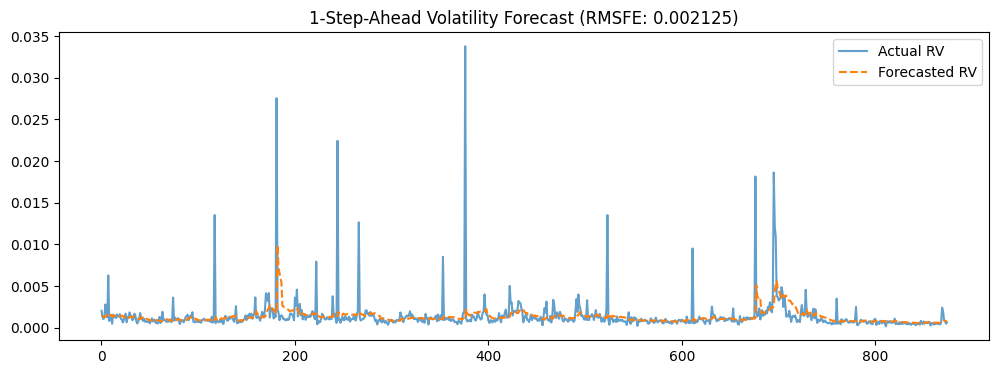

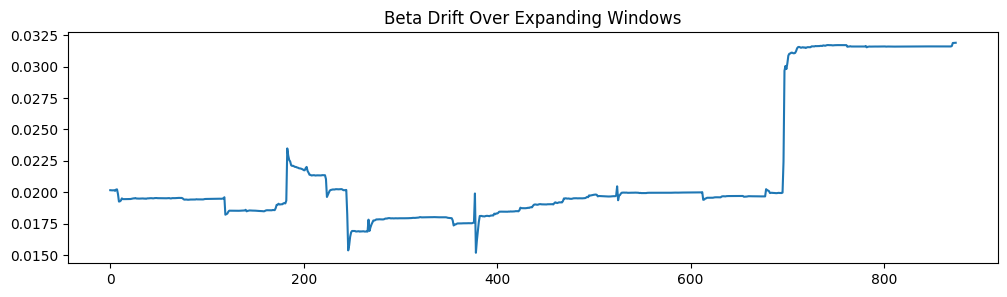

In [12]:
# Run the full pipeline
rmsfe_val, y_pred, betas, y_test = FSP(data)

# 1. Plot actual vs predicted volatility
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(y_test.numpy(), label='Actual RV', alpha=0.7)
plt.plot(y_pred.numpy(), label='Forecasted RV', linestyle='--')
plt.title(f'1-Step-Ahead Volatility Forecast (RMSFE: {rmsfe_val:.6f})')
plt.legend()
plt.show()

# 2. Plot parameter drift over time for a feature (e.g., daily negative semivariance)
plt.figure(figsize=(12, 3))
plt.plot(betas[:, 1].numpy())  # Index 1 = first feature after constant
plt.title('Beta Drift Over Expanding Windows')
plt.show()